In [1]:
# =====================================================================
# Part I - Finance - TEMPLATE
# =====================================================================
# The framework (finance_toolkit) fixes two things for everyone: how
# the data is loaded, and how a score panel is scored into a PnL,
# Sharpe and turnover.  Everything in the middle is yours.
#
# THE FLOW:
#   1. data is loaded for you (same for the whole class),
#   2. YOU build a SUPERSET of named features (FREE 1),
#   3. YOU write ONE recipe build_alpha(config) (FREE 2): a config
#      (feature subset, model, hyperparams) -> a trained model ->
#      scores -> positions -> its daily PnL,
#   4. YOU loop that recipe over MANY configs (FREE 3) to make many alphas,
#   5. the framework evaluates every alpha (Sharpe, turnover, ...),
#      shows the correlation between them, and keeps the best
#      un-correlated set.
#
# Your model only has to satisfy the MODEL CONTRACT:
#
#     model.predict(feat_t) -> scores
#     feat_t : float tensor (days, stocks, features)
#     scores : float tensor (days, stocks)
#
# Everything is a "panel": a table of shape (days x stocks).  Every
# operator takes panels and returns a panel of the same shape.

# Stage 0: Imports and Setup

## Data compatibility check

The supplied `prices_close.csv` uses a different date format from the other
price panels. Before loading the data, the close-price dates are normalised
only when the original DD/MM/YYYY format is detected.

No observations are removed or otherwise modified.

In [3]:
# =====================================================================
# Local data-package compatibility fix
# =====================================================================
# The provided prices_close.csv uses DD/MM/YYYY dates, whereas the
# other supplied price panels use YYYY-MM-DD.  Normalize close dates
# only when the original DD/MM/YYYY format is detected.

import pandas as pd
import re

close_path = "../data/prices_close.csv"

date_sample = pd.read_csv(
    close_path,
    usecols=["Date"],
    nrows=1
)["Date"].iloc[0]

if re.fullmatch(
    r"\d{2}/\d{2}/\d{4}",
    str(date_sample)
):
    close_raw = pd.read_csv(
        close_path,
        index_col="Date"
    )

    close_raw.index = pd.to_datetime(
        close_raw.index,
        format="%d/%m/%Y"
    )

    close_raw.index = close_raw.index.strftime(
        "%Y-%m-%d"
    )

    close_raw.to_csv(close_path)

    print(
        "Normalized prices_close.csv dates "
        "from DD/MM/YYYY to YYYY-MM-DD."
    )

else:
    print(
        "prices_close.csv dates already normalized."
    )

prices_close.csv dates already normalized.


# Stage 1: Data understanding & sanity checks

In [4]:
import os
import json
import numpy
import torch
import financial_toolkit as toolkit

# =====================================================================
# FIXED 1
# =====================================================================
SEED = 42
torch.manual_seed(SEED)
numpy.random.seed(SEED)
torch.set_num_threads(4)

# Everything up to SPLIT_DATE trains; the rest is a local hold-out.
DATA_DIR = "../data"
panels = toolkit.load_prices(DATA_DIR)

# Target and valid trading mask
forward_returns = toolkit.forward_return(panels["returns"])
mask = toolkit.valid_mask(panels, min_history=60)

all_dates = panels["close"].index
tickers = panels["close"].columns

print(
    "panel:", panels["close"].shape,
    "dates", all_dates.min().date(),
    "to", all_dates.max().date()
)

# Local train / hold-out split
SPLIT_DATE = "2020-01-01"
is_train = all_dates < SPLIT_DATE
is_test = ~is_train

print(
    "train days:", int(is_train.sum()),
    "test days:", int(is_test.sum())
)

close = panels["close"]
open_ = panels["open"]
high = panels["high"]
low = panels["low"]
volume = panels["volume"]
returns = panels["returns"]

sector, industry = toolkit.load_groups("../data/groups.csv")

panel: (2669, 2994) dates 2013-01-02 to 2023-06-30
train days: 1775 test days: 894


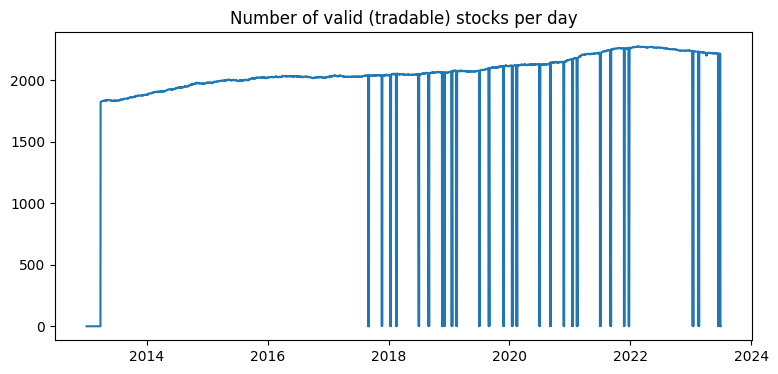

forward_returns stats:
 count    5.521390e+06
mean     8.884333e-04
std      4.649686e-02
min     -8.000000e-01
25%     -1.135589e-02
50%      0.000000e+00
75%      1.193063e-02
max      4.000000e+00
dtype: float64

mean abs diff (returns vs close.pct_change): 0.042930212886876325

biggest finite divergence days:
Date
2017-05-26    22199.019608
2019-03-27    19979.000000
2021-09-16    10873.208333
2019-08-01     3048.666667
2020-05-08     1877.977273
dtype: float64

fraction of volume observations <= 0: 0.010235626006696506

stocks missing sector code: 1 / 2994


In [5]:
import matplotlib.pyplot as plt

# How the tradable universe changes over time
valid_count = mask.sum(axis=1)

plt.figure(figsize=(9, 4))
plt.plot(valid_count)
plt.title("Number of valid (tradable) stocks per day")
plt.show()

# Target sanity check
print("forward_returns stats:\n", forward_returns.stack().describe())

# Confirm why return features must use `returns`
# rather than raw-close percentage changes.
close_pct = close.pct_change(fill_method=None)
diff = (returns - close_pct).abs()
diff_clean = diff.replace([numpy.inf, -numpy.inf], numpy.nan)

print(
    "\nmean abs diff (returns vs close.pct_change):",
    diff_clean.stack().mean()
)

print("\nbiggest finite divergence days:")
print(
    diff_clean.max(axis=1)
    .sort_values(ascending=False)
    .head(5)
)

# Volume anomalies
print(
    "\nfraction of volume observations <= 0:",
    (volume.stack() <= 0).mean()
)

# Groups coverage
print(
    "\nstocks missing sector code:",
    sector.isna().sum(), "/", len(sector)
)

### Sanity check: sparse dates and end-of-panel targets

The following check is diagnostic only: the raw panels are not modified.

Some dates may contain very few valid securities because of market holidays,
missing observations, or other calendar effects. These dates are left untouched
because data loading and target construction belong to the fixed framework.

The final dates of the sample can also have an empty valid mask because the
forward-return target requires future observations that do not exist beyond the
end of the dataset. This is expected and prevents look-ahead.

In [6]:
# Diagnostic only — do not remove or modify any dates.
valid_count = mask.sum(axis=1)

low_valid_days = valid_count[
    valid_count <
    valid_count.rolling(10, min_periods=1).median() * 0.5
]

print("number of unusually low-validity days:", len(low_valid_days))
print("\nfirst low-validity days:")
print(low_valid_days.head(10))

print("\nlast low-validity days:")
print(low_valid_days.tail(10))

# Inspect the last two dates, where a forward target may be unavailable.
print("\nlast dates in panel:")
for d in all_dates[-3:]:
    print(
        d,
        "close:", close.loc[d].notna().sum(),
        "returns:", returns.loc[d].notna().sum(),
        "valid mask:", int(mask.loc[d].sum())
    )

number of unusually low-validity days: 56

first low-validity days:
Date
2017-08-31    0
2017-09-04    0
2017-11-21    1
2017-11-23    1
2018-01-11    1
2018-01-15    1
2018-02-15    1
2018-02-19    1
2018-07-02    1
2018-07-04    1
dtype: int64

last low-validity days:
Date
2021-12-22    1
2021-12-24    0
2023-01-12    1
2023-01-16    1
2023-02-16    1
2023-02-20    1
2023-06-15    1
2023-06-19    1
2023-06-29    0
2023-06-30    0
dtype: int64

last dates in panel:
2023-06-28 00:00:00 close: 2228 returns: 2226 valid mask: 2215
2023-06-29 00:00:00 close: 2227 returns: 2224 valid mask: 0
2023-06-30 00:00:00 close: 2227 returns: 2225 valid mask: 0


## Stage 2: Feature engineering and alpha search

The feature set is designed to capture several distinct cross-sectional effects:
momentum, short-term reversal, volatility, intraday price behaviour, volume,
liquidity, sector/industry effects, market exposure and idiosyncratic risk.

All return-based features are built from the provided `returns` panel rather than
from percentage changes in raw close prices.

Each final feature is cross-sectionally normalised so that stocks are comparable
on the same scale on each day. Group-neutralised features use the provided sector
or industry classifications.

Only information available up to the current day is used in feature construction.
The hold-out period is not inspected during feature construction.

In [7]:
# =====================================================================
# >>> FREE 1 <<<   feature superset
# =====================================================================

def safe_div(a, b):
    """
    Element-wise division.
    Zero denominators are converted to NaN instead of +/-inf.
    """
    return a / b.where(b != 0)


# ---------------------------------------------------------------------
# Intermediate panels
# ---------------------------------------------------------------------

# Equal-weight market-return proxy
market_return = returns.mean(axis=1)

# Rolling market beta (60 trading observations)
market_cov = returns.rolling(60).cov(market_return)
market_var = market_return.rolling(60).var()
beta = market_cov.div(market_var.where(market_var != 0), axis=0)

# Residual return after removing market exposure
residual_return = returns.sub(
    beta.mul(market_return, axis=0)
)

# Actual sector return
sector_returns = toolkit.cs_groupmean(returns, sector)

# Same-day intraday return
intraday_return_raw = safe_div(close - open_, open_)

# Split-safe synthetic cumulative level built from the provided returns
synthetic_level = (1.0 + returns).cumprod()

rolling_high_252 = synthetic_level.rolling(
    252, min_periods=60
).max()

# Dollar-volume proxy
dollar_volume = volume.where(volume > 0) * close


# ---------------------------------------------------------------------
# Final feature superset
# Every feature ends with a cross-sectional transformation.
# ---------------------------------------------------------------------

all_features = {

    # ---------------------------------------------------------------
    # Original worked feature
    # ---------------------------------------------------------------
    "feature_1": toolkit.cs_zscore(
        toolkit.cs_groupmean(
            toolkit.ts_zscore(open_ - close, 20),
            sector
        )
    ),

    # ---------------------------------------------------------------
    # Momentum
    # ---------------------------------------------------------------
    "momentum_20": toolkit.cs_zscore(
        toolkit.ts_mean(returns, 20)
    ),

    "momentum_60": toolkit.cs_zscore(
        toolkit.ts_mean(returns, 60)
    ),

    "momentum_20_neutral": toolkit.cs_zscore(
        toolkit.ts_mean(returns, 20),
        sector
    ),

    "momentum_industry_neutral": toolkit.cs_zscore(
        toolkit.ts_mean(returns, 20),
        industry
    ),

    # ---------------------------------------------------------------
    # Short-term reversal
    # ---------------------------------------------------------------
    "reversal_5": toolkit.cs_zscore(
        -toolkit.ts_mean(returns, 5)
    ),

    "reversal_1": toolkit.cs_zscore(
        -returns
    ),

    # ---------------------------------------------------------------
    # Volatility / risk
    # ---------------------------------------------------------------
    "volatility_20": toolkit.cs_zscore(
        toolkit.ts_std(returns, 20)
    ),

    "volatility_ratio": toolkit.cs_zscore(
        safe_div(
            toolkit.ts_std(returns, 20),
            toolkit.ts_std(returns, 60)
        )
    ),

    "risk_adj_momentum": toolkit.cs_zscore(
        safe_div(
            toolkit.ts_mean(returns, 20),
            toolkit.ts_std(returns, 20)
        )
    ),

    # ---------------------------------------------------------------
    # Same-day price behaviour
    # ---------------------------------------------------------------
    "range_pos": toolkit.cs_zscore(
        safe_div(close - low, high - low)
    ),

    "intraday_range": toolkit.cs_zscore(
        safe_div(high - low, close)
    ),

    "intraday_return": toolkit.cs_zscore(
        intraday_return_raw
    ),

    "overnight_proxy": toolkit.cs_zscore(
        returns - intraday_return_raw
    ),

    # ---------------------------------------------------------------
    # Volume / liquidity
    # ---------------------------------------------------------------
    "volume_trend": toolkit.cs_zscore(
        toolkit.ts_zscore(
            volume.where(volume > 0),
            20
        )
    ),

    "illiquidity": toolkit.cs_zscore(
        toolkit.ts_mean(
            safe_div(
                returns.abs(),
                dollar_volume
            ),
            20
        )
    ),

    # ---------------------------------------------------------------
    # Long-horizon price position
    # ---------------------------------------------------------------
    "dist_from_high": toolkit.cs_zscore(
        safe_div(
            synthetic_level,
            rolling_high_252
        )
    ),

    # ---------------------------------------------------------------
    # Distribution shape
    # ---------------------------------------------------------------
    "return_skew": toolkit.cs_zscore(
        returns.rolling(20).skew()
    ),

    # ---------------------------------------------------------------
    # Market / idiosyncratic risk
    # ---------------------------------------------------------------
    "market_beta": toolkit.cs_zscore(
        beta
    ),

    "idio_vol": toolkit.cs_zscore(
        toolkit.ts_std(
            residual_return,
            20
        )
    ),

    # ---------------------------------------------------------------
    # Sector-level momentum
    # ---------------------------------------------------------------
    "sector_momentum": toolkit.cs_zscore(
        toolkit.ts_mean(
            sector_returns,
            20
        )
    ),
}


# Build all feature panels once
all_feature_panel = toolkit.build_features(
    all_features,
    panels
)

all_feature_names = sorted(all_feature_panel)

print(
    "features available:",
    all_feature_names
)

/usr/local/lib/python3.13/dist-packages/pandas/core/window/rolling.py:611: RuntimeWarning: All-NaN slice encountered
  return func(x, start, end, min_periods, *numba_args)


features available: ['dist_from_high', 'feature_1', 'idio_vol', 'illiquidity', 'intraday_range', 'intraday_return', 'market_beta', 'momentum_20', 'momentum_20_neutral', 'momentum_60', 'momentum_industry_neutral', 'overnight_proxy', 'range_pos', 'return_skew', 'reversal_1', 'reversal_5', 'risk_adj_momentum', 'sector_momentum', 'volatility_20', 'volatility_ratio', 'volume_trend']


In [8]:
# =====================================================================
# Feature sanity checks
# =====================================================================

print("number of features:", len(all_feature_panel))
print()

for name, panel in all_feature_panel.items():

    # Every feature must have exactly the same panel structure.
    assert panel.shape == close.shape, f"{name}: wrong shape"
    assert panel.index.equals(close.index), f"{name}: wrong dates"
    assert panel.columns.equals(close.columns), f"{name}: wrong tickers"

    values = panel.to_numpy(dtype=float)

    nan_frac = numpy.isnan(values).mean()
    inf_count = numpy.isinf(values).sum()

    finite_panel = panel.replace(
        [numpy.inf, -numpy.inf],
        numpy.nan
    )

    finite_values = finite_panel.stack()

    mean_value = finite_values.mean()
    std_value = finite_values.std()

    print(
        f"{name:28s} "
        f"nan_frac={nan_frac:.3f}  "
        f"inf={inf_count:5d}  "
        f"mean={mean_value: .4f}  "
        f"std={std_value:.4f}"
    )

    assert inf_count == 0, f"{name}: contains infinite values"
    assert nan_frac < 1.0, f"{name}: entirely NaN"

print("\nAll feature sanity checks passed.")

number of features: 21

feature_1                    nan_frac=0.454  inf=    0  mean= 0.0000  std=0.9998
momentum_20                  nan_frac=0.450  inf=    0  mean=-0.0000  std=0.9998
momentum_60                  nan_frac=0.622  inf=    0  mean=-0.0000  std=0.9998
momentum_20_neutral          nan_frac=0.450  inf=    0  mean=-0.0000  std=0.9975
momentum_industry_neutral    nan_frac=0.451  inf=    0  mean= 0.0000  std=0.9840
reversal_5                   nan_frac=0.341  inf=    0  mean= 0.0000  std=0.9998
reversal_1                   nan_frac=0.309  inf=    0  mean= 0.0000  std=0.9998
volatility_20                nan_frac=0.450  inf=    0  mean=-0.0000  std=0.9998
volatility_ratio             nan_frac=0.624  inf=    0  mean=-0.0000  std=0.9998
risk_adj_momentum            nan_frac=0.453  inf=    0  mean= 0.0000  std=0.9998
range_pos                    nan_frac=0.318  inf=    0  mean= 0.0000  std=0.9998
intraday_range               nan_frac=0.308  inf=    0  mean=-0.0000  std=0.9998
intr

In [9]:
# =====================================================================
# >>> FREE 2 <<<   one reusable alpha-building recipe
# =====================================================================

def build_alpha(config):
    """
    Train and evaluate one candidate alpha.

    Parameters
    ----------
    config : dict
        Required:
            features : list[str]

        Optional:
            model_kind  : "mlp" or "lstm"
            hidden      : hidden dimension
            epochs      : number of training epochs
            lr          : learning rate
            weight_decay: optimizer weight decay
            universe    : optional boolean (days x stocks) panel

    Returns
    -------
    model :
        trained PyTorch model
    positions :
        hold-out positions panel
    pnl :
        hold-out daily PnL
    features :
        ordered list of feature names used by the model
    """

    # ---------------------------------------------------------------
    # 1. Read and validate the configuration
    # ---------------------------------------------------------------

    if "features" not in config:
        raise KeyError("config must contain a 'features' entry")

    features = list(config["features"])

    if len(features) == 0:
        raise ValueError("An alpha must use at least one feature")

    if len(features) != len(set(features)):
        raise ValueError(
            f"Duplicate features in config: {features}"
        )

    unknown_features = sorted(
        set(features) - set(all_feature_panel)
    )

    if unknown_features:
        raise KeyError(
            f"Unknown features: {unknown_features}"
        )

    # Keep feature ordering deterministic.
    features = sorted(features)

    model_kind = str(
        config.get("model_kind", "lstm")
    ).lower()

    hidden = int(
        config.get("hidden", 32)
    )

    epochs = int(
        config.get("epochs", 8)
    )

    lr = float(
        config.get("lr", 1e-3)
    )

    weight_decay = float(
        config.get("weight_decay", 0.0)
    )

    universe = config.get(
        "universe", None
    )

    if model_kind not in {"mlp", "lstm"}:
        raise ValueError(
            "model_kind must be either 'mlp' or 'lstm'"
        )

    if hidden <= 0:
        raise ValueError("hidden must be positive")

    if epochs <= 0:
        raise ValueError("epochs must be positive")

    if lr <= 0:
        raise ValueError("lr must be positive")

    if weight_decay < 0:
        raise ValueError(
            "weight_decay cannot be negative"
        )


    # ---------------------------------------------------------------
    # 2. Stack only the requested features
    # ---------------------------------------------------------------

    selected_features = {
        name: all_feature_panel[name]
        for name in features
    }

    feature_array, _ = toolkit.stack_features(
        selected_features
    )


    # ---------------------------------------------------------------
    # 3. Build the active trading mask
    # ---------------------------------------------------------------

    if universe is None:
        active_mask = mask
    else:
        if universe.shape != mask.shape:
            raise ValueError(
                "universe must have the same shape as mask"
            )

        if not universe.index.equals(mask.index):
            raise ValueError(
                "universe dates do not match mask dates"
            )

        if not universe.columns.equals(mask.columns):
            raise ValueError(
                "universe tickers do not match mask tickers"
            )

        active_mask = mask & universe


    # ---------------------------------------------------------------
    # 4. Convert panels to tensors and split train / hold-out
    # ---------------------------------------------------------------

    feat_t, label_t, valid_t = toolkit.make_tensors(
        feature_array,
        forward_returns,
        active_mask
    )

    train_ds = toolkit.DayDataset(
        feat_t,
        label_t,
        valid_t,
        is_train
    )

    holdout_ds = toolkit.DayDataset(
        feat_t,
        label_t,
        valid_t,
        is_test
    )


    # ---------------------------------------------------------------
    # 5. Reproducible model construction
    # ---------------------------------------------------------------

    torch.manual_seed(SEED)
    numpy.random.seed(SEED)

    if model_kind == "mlp":

        model = toolkit.MLP(
            len(features),
            hidden=(hidden,)
        )

    else:

        model = toolkit.LSTM(
            len(features),
            hidden_size=hidden
        )


    # ---------------------------------------------------------------
    # 6. Train
    # ---------------------------------------------------------------

    model, _ = toolkit.train(
        model,
        train_ds,
        holdout_ds,
        epochs=epochs,
        lr=lr,
        weight_decay=weight_decay
    )


    # ---------------------------------------------------------------
    # 7. Generate scores and the hold-out long/short book
    # ---------------------------------------------------------------

    scores = toolkit.predict_scores(
        model,
        feat_t,
        all_dates,
        tickers
    )

    book = toolkit.scores_to_positions(
        scores,
        active_mask
    )

    positions = book.loc[is_test]


    # ---------------------------------------------------------------
    # 8. Hold-out PnL
    # ---------------------------------------------------------------

    pnl = toolkit.simulate(
        positions,
        forward_returns
    )


    return model, positions, pnl, features

### FREE 3: systematic alpha search

The search varies both the information supplied to the model and the model
architecture.

Feature subsets were chosen to represent distinct economic mechanisms rather
than many minor variations of the same signal. The search includes standalone
signals as well as a smaller number of deliberately mixed feature sets.

For each subset, both MLP and LSTM models are tested with two hidden dimensions.
All candidates are trained using the same fixed random seed and are evaluated
only on the local hold-out period.

The objective is not simply to maximise the Sharpe ratio of one model, but to
find a collection of individually strong alphas whose hold-out PnLs are also
sufficiently different from one another.

In [10]:
# =====================================================================
# >>> FREE 3 <<<   systematic search over candidate alphas
# =====================================================================


# ---------------------------------------------------------------------
# 1. Feature subsets
# ---------------------------------------------------------------------
#
# First use many economically distinct single-feature models.
# This is useful because the final requirement rewards PnL diversity,
# not only the strongest individual Sharpe.
#
# Then add selected multi-feature combinations that mix distinct
# mechanisms rather than near-duplicates.
# ---------------------------------------------------------------------

feature_subsets = [

    # ---------------------------------------------------------------
    # Standalone signals
    # ---------------------------------------------------------------
    ["feature_1"],

    ["momentum_20"],
    ["momentum_60"],
    ["momentum_20_neutral"],
    ["momentum_industry_neutral"],

    ["reversal_1"],
    ["reversal_5"],

    ["volatility_20"],
    ["volatility_ratio"],
    ["risk_adj_momentum"],

    ["range_pos"],
    ["intraday_range"],
    ["intraday_return"],
    ["overnight_proxy"],

    ["volume_trend"],
    ["illiquidity"],

    ["dist_from_high"],
    ["return_skew"],

    ["market_beta"],
    ["idio_vol"],

    ["sector_momentum"],


    # ---------------------------------------------------------------
    # Selected mixed mechanisms
    # ---------------------------------------------------------------

    # Medium/long horizon momentum
    ["momentum_20", "momentum_60"],

    # Momentum + reversal
    ["momentum_20", "reversal_5"],

    # Sector-neutral momentum + short reversal
    ["momentum_20_neutral", "reversal_1"],

    # Industry-relative momentum + liquidity
    ["momentum_industry_neutral", "illiquidity"],

    # Risk-adjusted trend + volatility regime
    ["risk_adj_momentum", "volatility_ratio"],

    # Intraday price location + overnight component
    ["range_pos", "overnight_proxy"],

    # Intraday movement + liquidity
    ["intraday_range", "illiquidity"],

    # Volume + price momentum
    ["volume_trend", "momentum_20"],

    # Long-horizon position + short reversal
    ["dist_from_high", "reversal_1"],

    # Distribution shape + idiosyncratic risk
    ["return_skew", "idio_vol"],

    # Market exposure + idiosyncratic risk
    ["market_beta", "idio_vol"],

    # Sector trend + stock-specific momentum
    ["sector_momentum", "momentum_20_neutral"],

    # A balanced multi-mechanism model
    [
        "momentum_20",
        "reversal_5",
        "volatility_ratio",
        "illiquidity"
    ],

    # Price behaviour + risk
    [
        "intraday_return",
        "overnight_proxy",
        "idio_vol"
    ],
]


# ---------------------------------------------------------------------
# 2. Hyperparameter grid
# ---------------------------------------------------------------------

model_kinds = ["mlp", "lstm"]
hidden_sizes = [16, 32]

BASE_EPOCHS = 8
BASE_LR = 1e-3
BASE_WEIGHT_DECAY = 0.0


# ---------------------------------------------------------------------
# 3. Construct configs
# ---------------------------------------------------------------------

configs = []

for features in feature_subsets:
    for model_kind in model_kinds:
        for hidden in hidden_sizes:

            configs.append({
                "features": features,
                "model_kind": model_kind,
                "hidden": hidden,
                "epochs": BASE_EPOCHS,
                "lr": BASE_LR,
                "weight_decay": BASE_WEIGHT_DECAY,
            })


print("number of feature subsets:", len(feature_subsets))
print("number of candidate configs:", len(configs))


# ---------------------------------------------------------------------
# 4. Validate the grid before training anything
# ---------------------------------------------------------------------

for i, config in enumerate(configs):

    unknown = (
        set(config["features"])
        - set(all_feature_panel)
    )

    assert not unknown, (
        f"config {i} contains unknown features: {unknown}"
    )

    assert (
        config["model_kind"] in {"mlp", "lstm"}
    )

    assert config["hidden"] > 0
    assert config["epochs"] > 0
    assert config["lr"] > 0
    assert config["weight_decay"] >= 0


# Make sure no exact duplicate configs exist.
config_keys = [
    (
        tuple(sorted(c["features"])),
        c["model_kind"],
        c["hidden"],
        c["epochs"],
        c["lr"],
        c["weight_decay"],
    )
    for c in configs
]

assert len(config_keys) == len(set(config_keys)), \
    "Duplicate configs found in search grid"


print("config validation passed.")

number of feature subsets: 35
number of candidate configs: 140
config validation passed.


In [11]:
# =====================================================================
# Train all candidate alphas
# =====================================================================

trained = {}
positions = {}
alphas = {}
feature_sets = {}
alpha_configs = {}


for i, config in enumerate(configs):

    print(
        f"\n{'=' * 70}\n"
        f"alpha {i + 1}/{len(configs)} | "
        f"{config['model_kind'].upper()} | "
        f"hidden={config['hidden']} | "
        f"features={config['features']}\n"
        f"{'=' * 70}"
    )

    model, book, pnl, used_features = build_alpha(
        config
    )

    trained[i] = model
    positions[i] = book
    alphas[i] = pnl
    feature_sets[i] = used_features

    # Keep a copy of the exact configuration for diagnostics.
    alpha_configs[i] = {
        key: value
        for key, value in config.items()
        if key != "universe"
    }


print(
    "\nFinished training",
    len(alphas),
    "candidate alphas."
)


alpha 1/140 | MLP | hidden=16 | features=['feature_1']
epoch  0 | train loss 0.75666 ir -0.0043 tvr 1.0256 | val loss 0.60461 ir -0.0128 tvr 0.8718
epoch  1 | train loss 0.69823 ir 0.0369 tvr 1.0082 | val loss 0.73292 ir -0.0491 tvr 0.9638
epoch  2 | train loss 0.69700 ir 0.0160 tvr 0.9860 | val loss 0.62628 ir 0.0149 tvr 0.9212
epoch  3 | train loss 0.71792 ir -0.0081 tvr 0.9828 | val loss 0.59543 ir -0.0115 tvr 0.8639
epoch  4 | train loss 0.64453 ir 0.0204 tvr 0.9378 | val loss 0.63396 ir -0.0281 tvr 0.8858
epoch  5 | train loss 0.67972 ir -0.0229 tvr 0.9296 | val loss 0.59193 ir -0.0217 tvr 0.8502
epoch  6 | train loss 0.65104 ir 0.0061 tvr 0.9299 | val loss 0.62236 ir -0.0330 tvr 0.8694
epoch  7 | train loss 0.65235 ir 0.0003 tvr 0.9255 | val loss 0.65927 ir -0.0471 tvr 0.8922

alpha 2/140 | MLP | hidden=32 | features=['feature_1']
epoch  0 | train loss 0.87312 ir -0.0305 tvr 1.1161 | val loss 0.74191 ir 0.0249 tvr 1.0468
epoch  1 | train loss 0.81540 ir -0.0156 tvr 1.0730 | val 

In [12]:
# =====================================================================
# Candidate-pool diagnostic before FIXED 4
# =====================================================================

# Compute the official KPIs using the framework.
candidate_kpis = toolkit.compute_kpis(
    positions,
    forward_returns
)

# Assignment's individual requirements.
passing_ids = candidate_kpis[
    (candidate_kpis["sharpe"] > 1.2) &
    (candidate_kpis["turnover"] < 0.8)
].index.tolist()

print(
    "total candidate alphas:",
    len(alphas)
)

print(
    "alphas with Sharpe > 1.2 and turnover < 0.8:",
    len(passing_ids)
)

# Show the strongest individually qualifying candidates.
if passing_ids:
    passing_table = (
        candidate_kpis
        .loc[passing_ids]
        .sort_values("sharpe", ascending=False)
    )

    print("\nTop qualifying candidates:")
    print(
        passing_table[
            ["sharpe", "turnover"]
        ].head(20).round(4)
    )

    print("\nTheir configurations:")
    for i in passing_table.index[:20]:
        print(
            f"{i:3d} | "
            f"Sharpe={candidate_kpis.loc[i, 'sharpe']:.3f} | "
            f"turnover={candidate_kpis.loc[i, 'turnover']:.3f} | "
            f"{alpha_configs[i]}"
        )
else:
    print(
        "\nNo candidate currently satisfies both "
        "individual submission thresholds."
    )

total candidate alphas: 140
alphas with Sharpe > 1.2 and turnover < 0.8: 69

Top qualifying candidates:
     sharpe  turnover
51   3.7438    0.2843
55   3.7386    0.1958
47   3.5629    0.1394
95   3.5455    0.2222
23   3.5298    0.1412
139  3.5113    0.2430
22   3.4710    0.2626
111  3.4502    0.1756
50   3.4375    0.2767
46   3.4231    0.2678
107  3.4156    0.2310
110  3.3901    0.2113
106  3.3384    0.3039
19   3.2998    0.1857
94   3.2609    0.2589
99   3.2323    0.1845
138  3.2222    0.2210
15   3.2059    0.1838
83   3.1921    0.1888
135  3.1805    0.2158

Their configurations:
 51 | Sharpe=3.744 | turnover=0.284 | {'features': ['intraday_return'], 'model_kind': 'lstm', 'hidden': 32, 'epochs': 8, 'lr': 0.001, 'weight_decay': 0.0}
 55 | Sharpe=3.739 | turnover=0.196 | {'features': ['overnight_proxy'], 'model_kind': 'lstm', 'hidden': 32, 'epochs': 8, 'lr': 0.001, 'weight_decay': 0.0}
 47 | Sharpe=3.563 | turnover=0.139 | {'features': ['intraday_range'], 'model_kind': 'lstm', 'hidden'

per-alpha stats:
      sharpe  mean_daily_pnl  std_daily_pnl  total_pnl  max_drawdown  num_days  \
51   3.7438          0.0048         0.0203     4.2876       -0.1310     894.0   
55   3.7386          0.0056         0.0237     4.9971       -0.2104     894.0   
47   3.5629          0.0030         0.0135     2.7163       -0.1418     894.0   
95   3.5455          0.0031         0.0138     2.7568       -0.1310     894.0   
23   3.5298          0.0041         0.0183     3.6378       -0.1537     894.0   
..      ...             ...            ...        ...           ...       ...   
88  -1.2810         -0.0018         0.0227    -1.6342       -1.9333     894.0   
61  -1.3540         -0.0114         0.1332   -10.1580      -10.5693     894.0   
108 -1.3752         -0.0069         0.0797    -6.1687       -6.5115     894.0   
96  -1.3924         -0.0038         0.0435    -3.4132       -4.0690     894.0   
63  -1.6316         -0.0166         0.1617   -14.8618      -15.1583     894.0   

     turn

/content/drive/MyDrive/ML_Final_Project/Code - Directives/financial_toolkit.py:694: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


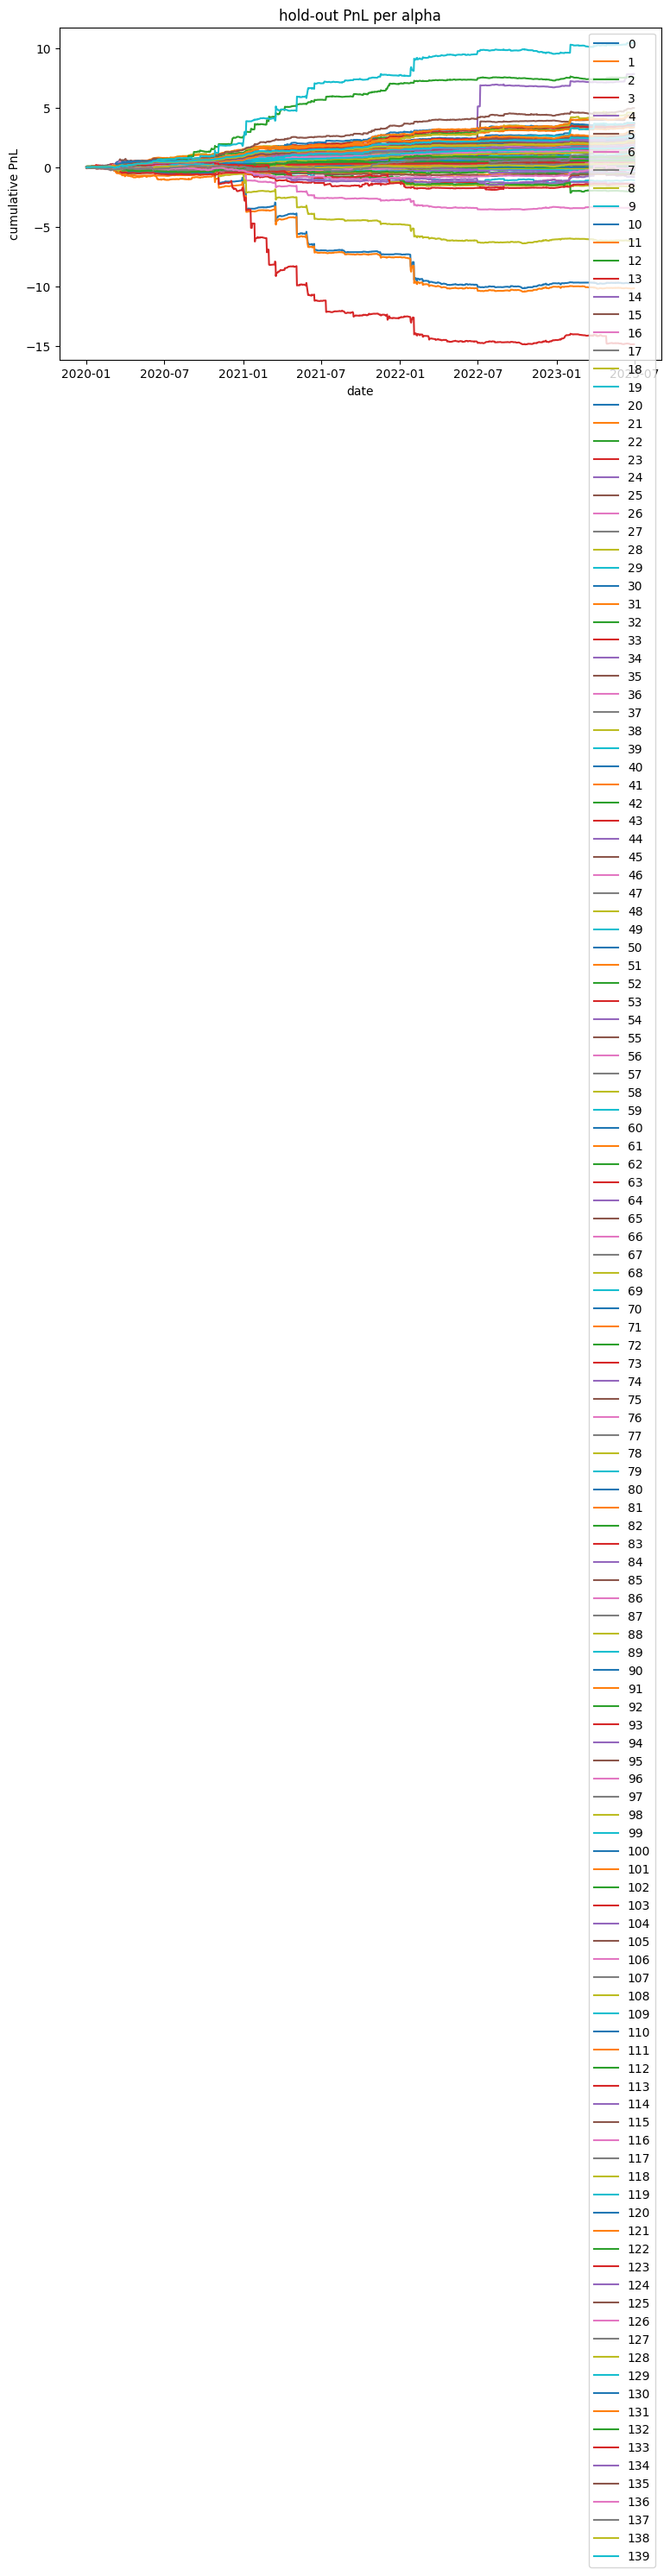

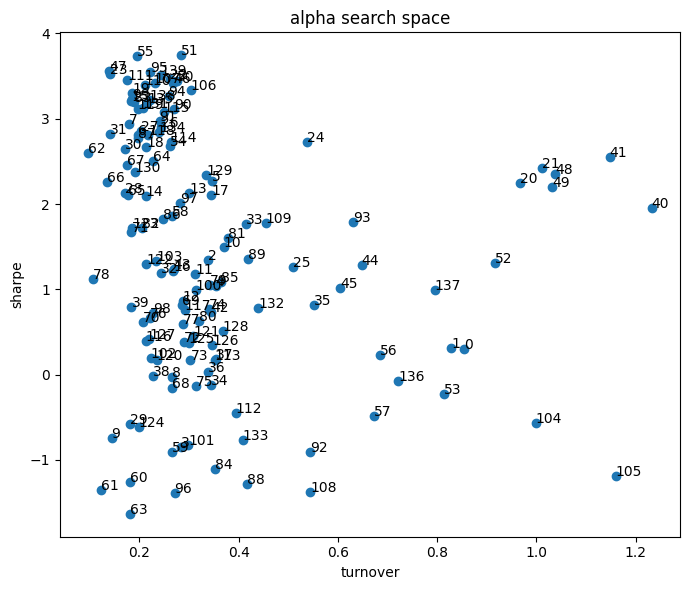

In [13]:
# =====================================================================
# FIXED 4 -- evaluate the alphas   (per alpha, then together)
# =====================================================================
# Per-alpha stats (Sharpe, total PnL, turnover, ...), the
# correlation between alphas, and the combined Sharpe of the best
# un-correlated set -- exactly what the grader does on its hidden
# period.

kpi_table = toolkit.compute_kpis(
    positions,
    forward_returns
)

print(
    "per-alpha stats:\n",
    kpi_table.round(4)
)

print(
    "\nPnL correlation:\n",
    toolkit.pnl_correlation(alphas).round(2)
)

kept = toolkit.select_uncorrelated(
    alphas,
    max_corr=0.5
)

print(
    "\nun-alike alphas kept:",
    kept
)

print(
    "combined Sharpe (kept):",
    round(
        toolkit.combined_sharpe(
            alphas,
            kept
        ),
        4
    )
)

# See the curves while developing (does not affect grading).
toolkit.plot_pnl(
    alphas,
    "hold-out PnL per alpha"
)

toolkit.plot_kpis(
    kpi_table
)

In [14]:
# =====================================================================
# Submission-ready alpha check
# =====================================================================
# FIXED 4 removes highly correlated candidates, but the final
# submission must also satisfy the individual Sharpe and turnover
# requirements.

kept_passing = [
    i for i in kept
    if (
        kpi_table.loc[i, "sharpe"] > 1.2
        and
        kpi_table.loc[i, "turnover"] < 0.8
    )
]

print(
    "uncorrelated alphas from FIXED 4:",
    len(kept)
)

print(
    "of these, passing Sharpe/turnover requirements:",
    len(kept_passing)
)

if kept_passing:

    final_check = (
        kpi_table
        .loc[kept_passing]
        [["sharpe", "turnover"]]
        .copy()
    )

    print(
        "\nQualifying uncorrelated alphas:"
    )

    print(
        final_check.round(4)
    )


    # -------------------------------------------------------------
    # Verify pairwise correlation explicitly
    # -------------------------------------------------------------

    passing_pnls = {
        i: alphas[i]
        for i in kept_passing
    }

    passing_corr = toolkit.pnl_correlation(
        passing_pnls
    )

    corr_values = passing_corr.to_numpy().copy()

    numpy.fill_diagonal(
        corr_values,
        numpy.nan
    )

    max_pairwise_corr = numpy.nanmax(
        corr_values
    )

    print(
        "\nmaximum pairwise correlation:",
        round(
            float(max_pairwise_corr),
            4
        )
    )

    print(
        "combined Sharpe:",
        round(
            toolkit.combined_sharpe(
                alphas,
                kept_passing
            ),
            4
        )
    )


    print(
        "\nConfigurations:"
    )

    for i in kept_passing:

        print(
            f"{i:3d} | "
            f"Sharpe={kpi_table.loc[i, 'sharpe']:.3f} | "
            f"turnover={kpi_table.loc[i, 'turnover']:.3f} | "
            f"{alpha_configs[i]}"
        )

uncorrelated alphas from FIXED 4: 52
of these, passing Sharpe/turnover requirements: 16

Qualifying uncorrelated alphas:
     sharpe  turnover
51   3.7438    0.2843
55   3.7386    0.1958
118  2.8119    0.2180
24   2.7217    0.5385
62   2.6008    0.0965
17   2.1007    0.3453
58   1.8625    0.2649
93   1.7883    0.6309
109  1.7819    0.4547
33   1.7647    0.4141
123  1.7217    0.1852
10   1.5018    0.3697
2    1.3487    0.3382
103  1.3275    0.2335
44   1.2900    0.6480
25   1.2589    0.5102

maximum pairwise correlation: 0.4974
combined Sharpe: 3.4604

Configurations:
 51 | Sharpe=3.744 | turnover=0.284 | {'features': ['intraday_return'], 'model_kind': 'lstm', 'hidden': 32, 'epochs': 8, 'lr': 0.001, 'weight_decay': 0.0}
 55 | Sharpe=3.739 | turnover=0.196 | {'features': ['overnight_proxy'], 'model_kind': 'lstm', 'hidden': 32, 'epochs': 8, 'lr': 0.001, 'weight_decay': 0.0}
118 | Sharpe=2.812 | turnover=0.218 | {'features': ['dist_from_high', 'reversal_1'], 'model_kind': 'lstm', 'hidden':

## Final submission subset

FIXED 4 identifies a set of mutually uncorrelated candidate alphas.
For the final submission, this set is restricted further to alphas that also
satisfy the assignment's individual performance requirements:

- Sharpe > 1.2
- turnover < 0.8
- pairwise correlation ≤ 0.5

The resulting submission set contains at least 10 alphas.

In [15]:
# =====================================================================
# Final submission subset
# =====================================================================

final_kept = kept_passing.copy()

assert len(final_kept) >= 10

assert (
    kpi_table.loc[
        final_kept,
        "sharpe"
    ] > 1.2
).all()

assert (
    kpi_table.loc[
        final_kept,
        "turnover"
    ] < 0.8
).all()


final_pnls = {
    i: alphas[i]
    for i in final_kept
}

final_corr = toolkit.pnl_correlation(
    final_pnls
)

corr_values = final_corr.to_numpy().copy()

numpy.fill_diagonal(
    corr_values,
    numpy.nan
)

final_max_corr = numpy.nanmax(
    corr_values
)

assert final_max_corr <= 0.5


print(
    "final number of alphas:",
    len(final_kept)
)

print(
    "minimum Sharpe:",
    round(
        float(
            kpi_table.loc[
                final_kept,
                "sharpe"
            ].min()
        ),
        4
    )
)

print(
    "maximum turnover:",
    round(
        float(
            kpi_table.loc[
                final_kept,
                "turnover"
            ].max()
        ),
        4
    )
)

print(
    "maximum pairwise correlation:",
    round(
        float(final_max_corr),
        4
    )
)

print(
    "combined Sharpe:",
    round(
        toolkit.combined_sharpe(
            alphas,
            final_kept
        ),
        4
    )
)


# FIXED 5 uses the variable `kept`.
# Point it to the verified final submission subset.
kept = final_kept

final number of alphas: 16
minimum Sharpe: 1.2589
maximum turnover: 0.648
maximum pairwise correlation: 0.4974
combined Sharpe: 3.4604


In [16]:
# =====================================================================
# FIXED 5 -- write the submission
# =====================================================================
# For every kept alpha, save two things: the trained model and the
# list of feature names it used.  Submit this folder together with
# your notebook (your feature definitions live in the notebook).
SUBMISSION_DIR = "../output"
os.makedirs(SUBMISSION_DIR, exist_ok=True)

for i in kept:
    torch.save(trained[i], os.path.join(SUBMISSION_DIR, "model_%s.pt" % i))

params = {
    "alphas": kept,
    "feature_sets": {i: feature_sets[i] for i in kept},
}
with open(os.path.join(SUBMISSION_DIR, "params.json"), "w") as handle:
    json.dump(params, handle, indent=2)

print("submission written to", os.path.abspath(SUBMISSION_DIR))

submission written to /content/drive/MyDrive/ML_Final_Project/output


In [17]:
# =====================================================================
# Final submission-file verification
# =====================================================================

submission_files = sorted(
    os.listdir(SUBMISSION_DIR)
)

model_files = sorted(
    f for f in submission_files
    if f.startswith("model_") and f.endswith(".pt")
)

with open(
    os.path.join(SUBMISSION_DIR, "params.json"),
    "r"
) as handle:
    saved_params = json.load(handle)

print("model files:", len(model_files))
print("alphas in params.json:", saved_params["alphas"])
print("number of alphas:", len(saved_params["alphas"]))
print("all files:", submission_files)

model files: 16
alphas in params.json: [51, 55, 118, 24, 62, 17, 58, 93, 109, 33, 123, 10, 2, 103, 44, 25]
number of alphas: 16
all files: ['model_10.pt', 'model_103.pt', 'model_109.pt', 'model_118.pt', 'model_123.pt', 'model_17.pt', 'model_2.pt', 'model_24.pt', 'model_25.pt', 'model_33.pt', 'model_44.pt', 'model_51.pt', 'model_55.pt', 'model_58.pt', 'model_62.pt', 'model_93.pt', 'params.json']


## Summary: data checks and final alpha selection

Several data-quality and robustness checks were performed before constructing
the candidate alphas.

1. `prices_close.csv` originally used DD/MM/YYYY dates while the remaining
   supplied panels used YYYY-MM-DD. A small idempotent compatibility step
   normalises the close-price dates only when the original format is detected.

2. Sparse / unusually low-validity dates were inspected diagnostically.
   No dates or observations were removed from the supplied panels.

3. The supplied `returns` panel was compared with `close.pct_change()` and
   substantial differences were observed on extreme dates, consistent with
   the assignment warning regarding stock splits. Therefore all return-based
   features were constructed from the supplied `returns` panel.

The systematic search evaluated 140 candidate alphas. Of these, 69 satisfied
the individual requirements of Sharpe > 1.2 and turnover < 0.8.

FIXED 4 identified a broad set of mutually uncorrelated candidates. The final
submission subset was then restricted to candidates that also satisfied the
individual performance requirements.

The final submission contains 16 alphas with:

- minimum Sharpe: 1.2589
- maximum turnover: 0.6480
- maximum pairwise PnL correlation: 0.4974
- combined Sharpe: 3.4604

Thus the final selected set satisfies the assignment requirements of at least
10 alphas, Sharpe > 1.2, turnover < 0.8, and maximum pairwise correlation
not exceeding 0.5.